# Datacentre Waste Heat Recovery (WHR) Assessment

This notebook uses an existing IT server thermal load.

**Workflow:** IT thermal load & weather data → Server-side heat transfer → CDU scheduling & energy balance → FW-side energy balance → WHR → Dry cooler and chiller power → Performance metrics → Exporting results



## Install necessary dependencies

Uncomment to install dependencies using python pip

In [1]:
#%pip install pathlib dataclasses numpy pandas matplotlib ipython coolprop openmeteo_requests requests-cache retry-requests

## 1. Setup and configuration
Change `YEAR`, `N_SERVERS` here.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from CoolProp.CoolProp import PropsSI
from CoolProp.HumidAirProp import HAPropsSI
from IPython.display import display

OUTPUT_DIR = Path("output/datacenter_WHR")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
YEAR = 2023
TIMEZONE = "Australia/Melbourne"
HOURS = pd.date_range(f"{YEAR}-01-01", f"{YEAR + 1}-01-01", freq="h", tz=TIMEZONE, inclusive="left").as_unit("ns")
N_SERVERS = 22125
print(f"Year: {YEAR} | Timezone: {TIMEZONE} | Hours: {len(HOURS):,} | Number of servers: {N_SERVERS}")

Year: 2023 | Timezone: Australia/Melbourne | Hours: 8,760 | Number of servers: 22125


## 2. IT Thermal Load

IT thermal load validation: PASSED
Number of servers:         22,125
Number of hourly samples:  8,760
Minimum IT thermal load:   653.3 kW
Maximum IT thermal load:   4,773.3 kW
Mean IT thermal load:      2,812.1 kW
Mean heat load per server: 127.1 W
Annual IT thermal energy:  24,634.2 MWh


,t,Heat Load (kW),Heat Load per Server (W)
0,0,3182.990,143.863955
1,3600,3100.755,140.147119
2,7200,2830.555,127.934689
3,10800,2478.120,112.005424
4,14400,2313.650,104.571751


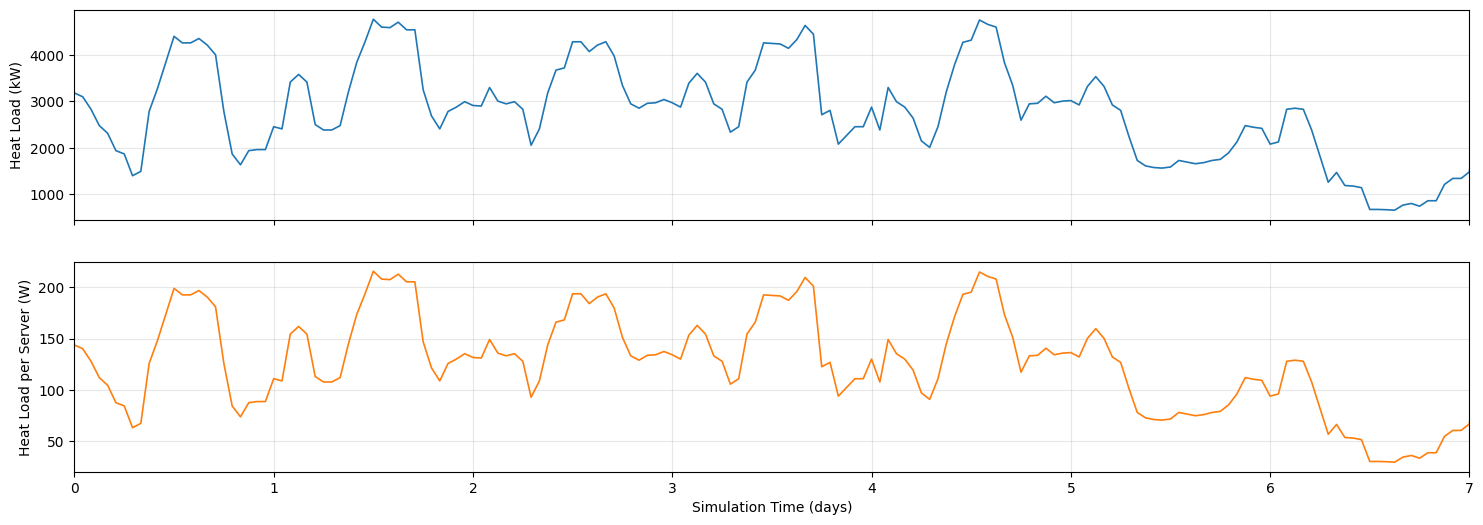

In [3]:
# =============================================================================
# IT THERMAL LOAD | Data Import, Validation and Analysis
# =============================================================================
# Import the hourly IT thermal load, calculate the heat generated per server,
# validate the dataset, and report key thermal load statistics.
# =============================================================================


# -----------------------------------------------------------------------------
# 1. Import IT Thermal Load Data
# -----------------------------------------------------------------------------

df = pd.read_csv("input/IT_thermal_load.csv")


# -----------------------------------------------------------------------------
# 2. Validate Input Data
# -----------------------------------------------------------------------------

required_cols = ["t", "Heat Load (kW)"]

if not all(col in df.columns for col in required_cols):
    raise ValueError(f"Missing required columns: {set(required_cols) - set(df.columns)}")

if df.empty:
    raise ValueError("IT thermal load dataset is empty")

if N_SERVERS <= 0:
    raise ValueError("N_SERVERS must be greater than zero")

if df[required_cols].isna().any().any():
    raise ValueError("IT thermal load dataset contains missing values")

if (df["Heat Load (kW)"] < 0).any():
    raise ValueError("IT thermal load cannot contain negative values")

if df["t"].duplicated().any():
    raise ValueError("Duplicate simulation timestamps detected")

if not df["t"].is_monotonic_increasing:
    raise ValueError("Simulation timestamps must be monotonically increasing")

if not np.allclose(np.diff(df["t"]), 3600):
    raise ValueError("IT thermal load must have hourly timestamps (3600 s intervals)")

print("IT thermal load validation: PASSED")

# -----------------------------------------------------------------------------
# 3. Calculate IT Thermal Load per Server
# -----------------------------------------------------------------------------

df["Heat Load per Server (W)"] = df["Heat Load (kW)"] * 1000 / N_SERVERS

# -----------------------------------------------------------------------------
# 4. Report IT Thermal Load Statistics
# -----------------------------------------------------------------------------

print(f"Number of servers:         {N_SERVERS:,}")
print(f"Number of hourly samples:  {len(df):,}")
print(f"Minimum IT thermal load:   {df['Heat Load (kW)'].min():,.1f} kW")
print(f"Maximum IT thermal load:   {df['Heat Load (kW)'].max():,.1f} kW")
print(f"Mean IT thermal load:      {df['Heat Load (kW)'].mean():,.1f} kW")
print(f"Mean heat load per server: {df['Heat Load per Server (W)'].mean():,.1f} W")
print(f"Annual IT thermal energy:  {df['Heat Load (kW)'].sum() / 1000:,.1f} MWh")

# -----------------------------------------------------------------------------
# 5. Display Validated Dataset
# -----------------------------------------------------------------------------

display(df.head(5))

# -----------------------------------------------------------------------------
# 6. Plot IT Thermal Load and Heat Load per Server
# -----------------------------------------------------------------------------

colours = ["tab:blue","tab:orange"]
fig,axes = plt.subplots(2,1,figsize=(18,6), sharex=True)
for idx,var in enumerate(["Heat Load (kW)","Heat Load per Server (W)"]):
    axes[idx].plot(df["t"]/86400, df[var], label=var, color=colours[idx], linewidth=1.2)
    axes[idx].set_ylabel(var)
    axes[idx].grid(True, alpha=0.3)
axes[-1].set_xlabel("Simulation Time (days)")
axes[-1].set_xlim([0,7])

plt.show()

## 3. Weather Data

Loaded local weather: output\datacenter_WHR\weather_2023.csv
Weather: 8,760 hourly samples | -1.1–34.7 °C | Mean 11.9 °C


,T_dry_degC,RH
datetime,,
2023-01-01 00:00:00+11:00,17.55,91.503876
2023-01-01 01:00:00+11:00,17.25,92.365820
2023-01-01 02:00:00+11:00,17.60,87.223410
2023-01-01 03:00:00+11:00,18.60,75.575500
2023-01-01 04:00:00+11:00,19.45,69.160930


Added weather columns: ['Ambient Temperature (C)', 'Relative Humidity (%)']


,t,Heat Load (kW),Heat Load per Server (W),Ambient Temperature (C),Relative Humidity (%)
0,0,3182.990,143.863955,17.55,91.503876
1,3600,3100.755,140.147119,17.25,92.365820
2,7200,2830.555,127.934689,17.60,87.223410
3,10800,2478.120,112.005424,18.60,75.575500
4,14400,2313.650,104.571751,19.45,69.160930


Missing temperature values: 0
Missing RH values: 0


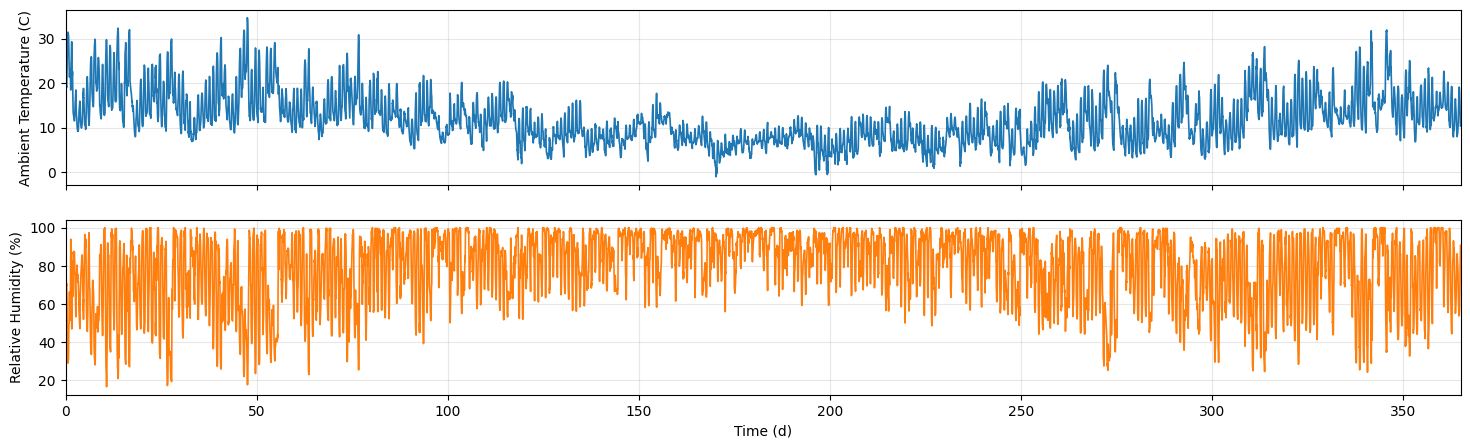

In [4]:
# =============================================================================
# WEATHER DATA | Import, Retrieval and Validation
# =============================================================================
# Load hourly ambient temperature and relative humidity for the simulation
# year. Prioritise local CSV files; otherwise retrieve historical weather
# data from Open-Meteo and save it for subsequent simulations.
# =============================================================================


# -----------------------------------------------------------------------------
# 1. Locate Existing Weather Data
# -----------------------------------------------------------------------------

weather_sources = [Path(f"weather_{YEAR}.csv"), OUTPUT_DIR / f"weather_{YEAR}.csv"]
existing_weather = next((p for p in weather_sources if p.exists()), None)


# -----------------------------------------------------------------------------
# 2. Load Weather Data from Local CSV
# -----------------------------------------------------------------------------

if existing_weather is not None:
    raw_weather = pd.read_csv(existing_weather)
    weather_times = pd.to_datetime(raw_weather["datetime"], utc=True).dt.tz_convert(TIMEZONE)
    weather = pd.DataFrame({
        "T_dry_degC": pd.to_numeric(raw_weather["T_dry_degC"], errors="raise").to_numpy(),
        "RH": pd.to_numeric(raw_weather["RH"], errors="raise").to_numpy(),
    }, index=pd.DatetimeIndex(weather_times))

    print(f"Loaded local weather: {existing_weather}")

else:

    # -------------------------------------------------------------------------
    # 3. Retrieve Historical Weather Data from Open-Meteo
    # -------------------------------------------------------------------------

    try:
        import openmeteo_requests
        import requests_cache
        from retry_requests import retry
    except ImportError as exc:
        raise ImportError(f"Provide weather_{YEAR}.csv beside the notebook or install openmeteo_requests, requests_cache and retry_requests") from exc

    # Configure cached API session
    cache = requests_cache.CachedSession(".openmeteo_cache", expire_after=-1)
    api = openmeteo_requests.Client(session=retry(cache, retries=5, backoff_factor=0.2))

    # Define location, simulation period and weather variables
    params = {"latitude": -37.5622, "longitude": 143.8503, "start_date": f"{YEAR}-01-01", "end_date": f"{YEAR}-12-31", "hourly": ["temperature_2m","relative_humidity_2m"], "timezone": TIMEZONE}

    # Retrieve hourly historical weather data
    hourly = api.weather_api("https://archive-api.open-meteo.com/v1/archive", params=params)[0].Hourly()

    # Construct timezone-aware hourly timestamps
    weather_index = pd.date_range(start=pd.to_datetime(hourly.Time(), unit="s", utc=True), end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True), freq=pd.Timedelta(seconds=hourly.Interval()), inclusive="left").tz_convert(TIMEZONE)

    # Assemble weather DataFrame
    weather = pd.DataFrame({"T_dry_degC": hourly.Variables(0).ValuesAsNumpy(),"RH": hourly.Variables(1).ValuesAsNumpy()}, index=weather_index)


# -----------------------------------------------------------------------------
# 4. Standardise Timestamps and Validate Weather Data
# -----------------------------------------------------------------------------

weather.index = weather.index.as_unit("ns")
weather.index.name = "datetime"

if not weather.index.equals(HOURS) or weather["T_dry_degC"].isna().any():
    raise ValueError("Hourly weather must cover the full simulation year with no missing timestamps or temperatures")


# -----------------------------------------------------------------------------
# 5. Export Weather Data
# -----------------------------------------------------------------------------

weather_csv = OUTPUT_DIR / f"weather_{YEAR}.csv"
weather.to_csv(weather_csv, index_label="datetime")


# -----------------------------------------------------------------------------
# 6. Display Weather Data Summary
# -----------------------------------------------------------------------------

print(f"Weather: {len(weather):,} hourly samples | {weather.T_dry_degC.min():.1f}–{weather.T_dry_degC.max():.1f} °C | Mean {weather.T_dry_degC.mean():.1f} °C")

display(weather.head(5))

# ---------------------------------------------------------
# Combine weather and IT thermal load into one dataframe
# ---------------------------------------------------------

weather_cols = ["Ambient Temperature (C)", "Relative Humidity (%)"]

if not all(col in df.columns for col in weather_cols):
    weather_merge = weather[["T_dry_degC", "RH"]].copy()
    weather_merge["t"] = (weather_merge.index - HOURS[0]).total_seconds()
    weather_merge.rename(columns={"T_dry_degC": weather_cols[0], "RH": weather_cols[1]}, inplace=True)

    # Only merge columns that do not already exist
    missing_cols = [col for col in weather_cols if col not in df.columns]
    df = df.merge(weather_merge[["t"] + missing_cols], on="t", how="left", validate="one_to_one")
    print(f"Added weather columns: {missing_cols}")
else:
    print("Ambient temperature and relative humidity already exist in df. Skipping merge.")

display(df.head(5))

# ---------------------------------------------------------
# Checking merged output
# ---------------------------------------------------------

print(f"Missing temperature values: {df['Ambient Temperature (C)'].isna().sum()}")
print(f"Missing RH values: {df['Relative Humidity (%)'].isna().sum()}")

# ---------------------------------------------------------
# Plot Data Centre & Server IT thermal load
# ---------------------------------------------------------

colours = ["tab:blue","tab:orange"]
fig,axes = plt.subplots(2,1,figsize=(18,5),sharex=True)
for idx,var in enumerate(["Ambient Temperature (C)","Relative Humidity (%)"]):
    axes[idx].plot(df["t"]/86400, df[var], label=var, color=colours[idx], linewidth=1.2)
    axes[idx].set_ylabel(var)
    axes[idx].grid(True, alpha=0.3)
axes[-1].set_xlabel("Time (d)")
axes[-1].set_xlim([0,365])

plt.show()

## 4. Server-side Heat Transfer

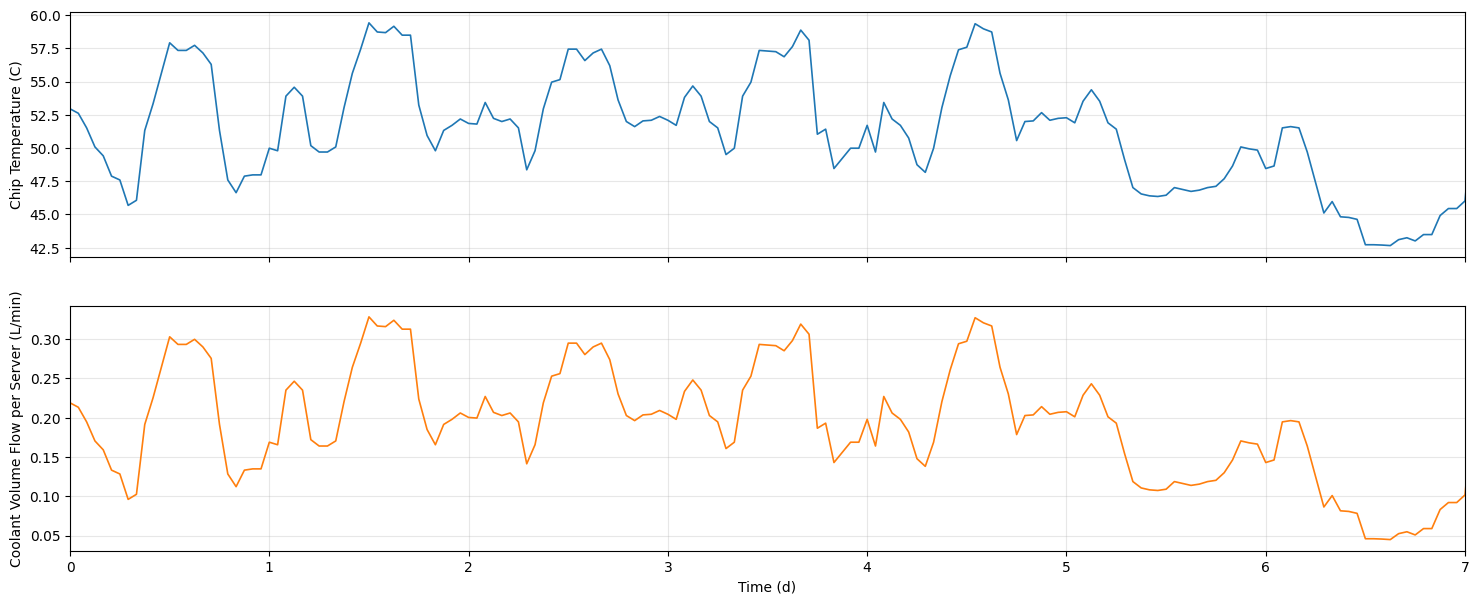

In [5]:
# ---------------------------------------------------------
# Server-side coolant (Glycol / Water mixture - 25 wt%.)
# ---------------------------------------------------------

FLUID = 'INCOMP::MEG-25%'

# ---------------------------------------------------------
# Coolant operation temperatures and pressure
# ---------------------------------------------------------

T_COOLANT_IN = 35.0
T_COOLANT_OUT = 45.0
P_COOLANT = 2e5

# ---------------------------------------------------------
# Server-side thermal resistance (Source: Fig 5, https://doi.org/rwsh)
# ---------------------------------------------------------

R_TH = 0.09 # K/W 

T_COOLANT_MEAN = (T_COOLANT_IN + T_COOLANT_OUT) / 2
df["Chip Temperature (C)"] = T_COOLANT_MEAN + df["Heat Load per Server (W)"] * R_TH

# ---------------------------------------------------------
# Coolant thermo-physical properties
# ---------------------------------------------------------

CP = PropsSI("C", "T", T_COOLANT_MEAN + 273.15, "P", P_COOLANT, FLUID)
RHO = PropsSI("D", "T", T_COOLANT_MEAN + 273.15, "P", P_COOLANT, FLUID)
H_COOLANT_OUT = PropsSI("H", "T", T_COOLANT_OUT + 273.15, "P", P_COOLANT, FLUID)
H_COOLANT_IN = PropsSI("H", "T", T_COOLANT_IN + 273.15, "P", P_COOLANT, FLUID)

# ---------------------------------------------------------
# Server-side mass and volumetric flow rates
# ---------------------------------------------------------

df["Coolant Mass Flow per Server (kg/s)"] = df["Heat Load per Server (W)"] / (H_COOLANT_OUT - H_COOLANT_IN)
df["Coolant Volume Flow per Server (L/min)"] = df["Coolant Mass Flow per Server (kg/s)"] / RHO * 60000
df["Total Coolant Mass Flow (kg/s)"] = df["Coolant Mass Flow per Server (kg/s)"] * N_SERVERS
df["Total Coolant Volume Flow (L/s)"] = df["Total Coolant Mass Flow (kg/s)"] / RHO * 1000

# ---------------------------------------------------------
# Plot chip and coolant temperatures
# ---------------------------------------------------------

colours = ["tab:blue","tab:orange"]
fig,axes = plt.subplots(2,1,figsize=(18,7),sharex=True)
for idx,var in enumerate(["Chip Temperature (C)","Coolant Volume Flow per Server (L/min)"]):
    axes[idx].plot(df["t"]/86400, df[var], label=var, color=colours[idx], linewidth=1.2)
    axes[idx].set_ylabel(var)
    axes[idx].grid(True, alpha=0.3)
axes[-1].set_xlabel("Time (d)")
axes[-1].set_xlim([0,7])

plt.show()

## 5. CDU Scheduling and Energy Balance

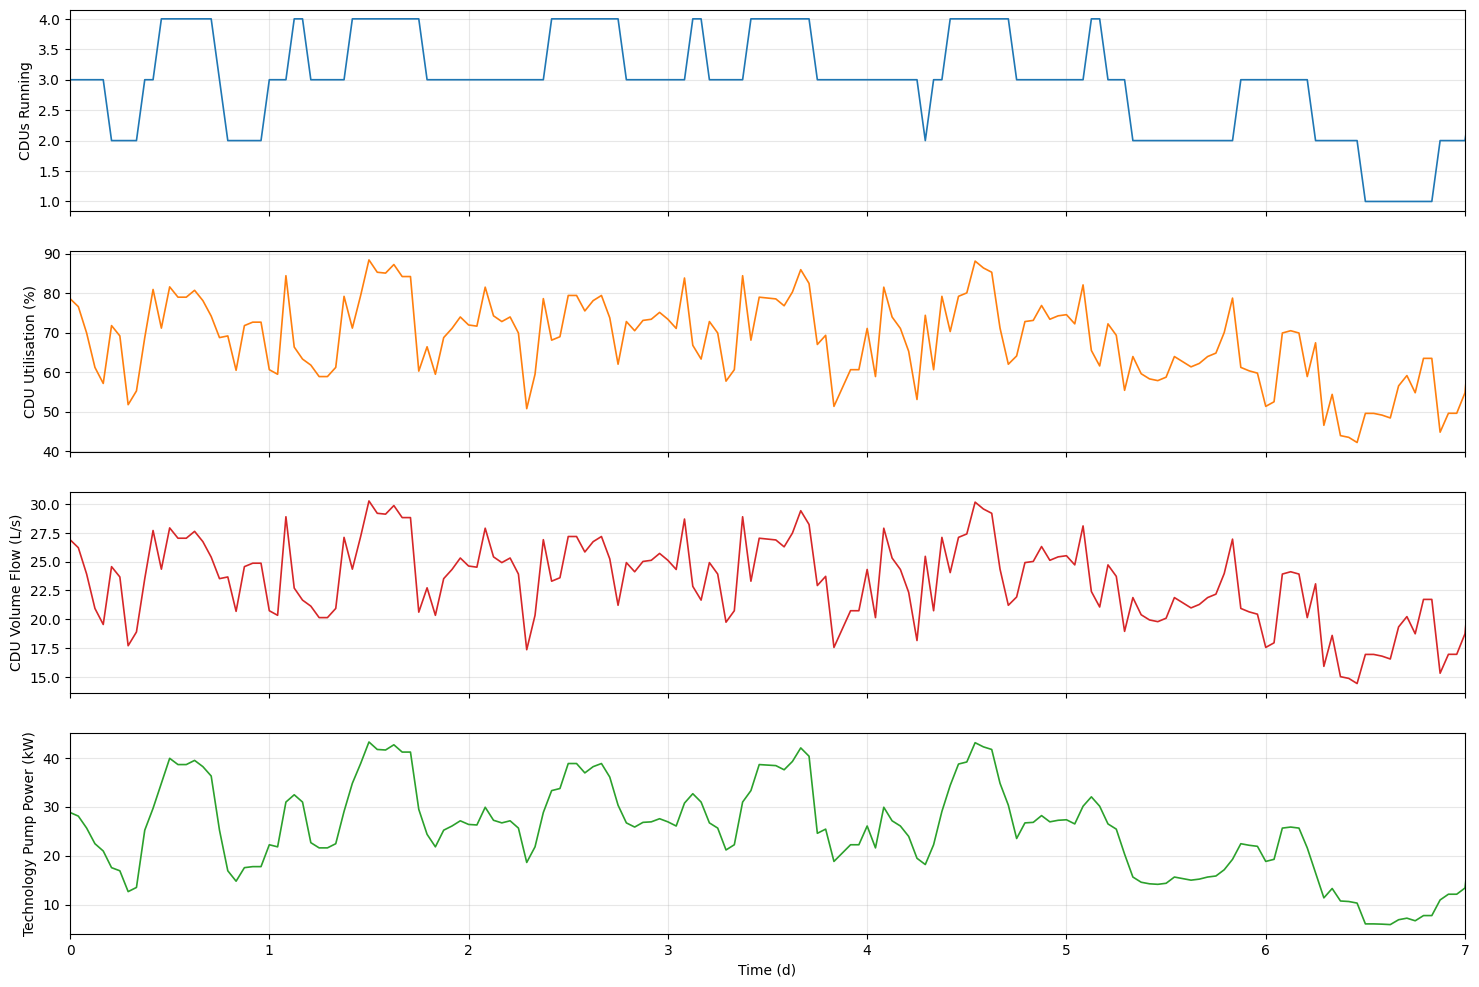

In [6]:
# ---------------------------------------------------------
# CDU Configuration: 5 × 1.35 MW CDUs, configured as 4 duty + 1 standby (N+1)
# ---------------------------------------------------------

N_CDU = 5
N_CDU_DUTY = 4
CDU_CAPACITY = 1350.0

# ---------------------------------------------------------
# Staging hysteresis
# ---------------------------------------------------------

CDU_STAGE_ON = 0.85
CDU_STAGE_OFF = 0.75

# ---------------------------------------------------------
# CDU scheduling
# ---------------------------------------------------------

cdus_running = np.zeros(len(df), dtype=int)
cdus_running[0] = int(np.ceil(df["Heat Load (kW)"].iloc[0] / (CDU_CAPACITY * CDU_STAGE_ON)))
cdus_running[0] = np.clip(cdus_running[0], 1, N_CDU_DUTY)

for i in range(1, len(df)):
    n = cdus_running[i - 1]
    load = df["Heat Load (kW)"].iloc[i]
    while n < N_CDU_DUTY and load > n * CDU_CAPACITY * CDU_STAGE_ON: n += 1
    while n > 1 and load < (n - 1) * CDU_CAPACITY * CDU_STAGE_OFF: n -= 1
    cdus_running[i] = n

# ---------------------------------------------------------
# Integration into dataframe
# ---------------------------------------------------------

df["CDUs Running"] = cdus_running
df["CDU Load (kW)"] = df["Heat Load (kW)"] / df["CDUs Running"]
df["CDU Utilisation (%)"] = df["CDU Load (kW)"] / CDU_CAPACITY * 100

# ---------------------------------------------------------
# Splitting the mass and volumetric flow rate per CDU
# ---------------------------------------------------------

df["CDU Mass Flow (kg/s)"] = df["Total Coolant Mass Flow (kg/s)"] / df["CDUs Running"]
df["CDU Volume Flow (L/s)"] = df["Total Coolant Volume Flow (L/s)"] / df["CDUs Running"]

# ---------------------------------------------------------
# Splitting the mass and volumetric flow rate per CDU
# ---------------------------------------------------------

df["Active CDU Capacity (kW)"] = df["CDUs Running"] * CDU_CAPACITY
df["CDU Capacity Margin (kW)"] = df["Active CDU Capacity (kW)"] - df["Heat Load (kW)"]

# ---------------------------------------------------------
# Technology-loop pump power (assuming all servers show the same inlet and outlet)
# ---------------------------------------------------------

TECH_LOOP_DP = 250000
TECH_PUMP_EFFICIENCY = 0.70
TECH_FLOW_PER_CDU_DESIGN = CDU_CAPACITY * 1000 / (CP * (T_COOLANT_OUT - T_COOLANT_IN)) / RHO
TECH_PUMP_POWER_DESIGN = TECH_LOOP_DP * TECH_FLOW_PER_CDU_DESIGN / TECH_PUMP_EFFICIENCY / 1000

# ---------------------------------------------------------
# Integration into dataframe
# ---------------------------------------------------------

df["Technology Flow per CDU (m3/s)"] = df["CDU Volume Flow (L/s)"] / 1000
df["Technology Pump Power per CDU (kW)"] = TECH_LOOP_DP * df["Technology Flow per CDU (m3/s)"] / TECH_PUMP_EFFICIENCY / 1000
df["Technology Pump Power (kW)"] = df["Technology Pump Power per CDU (kW)"] * df["CDUs Running"]

# ---------------------------------------------------------
# Plot chip and coolant temperatures
# ---------------------------------------------------------

colours=["tab:blue","tab:orange","tab:red","tab:green"]
fig,axes = plt.subplots(4,1,figsize=(18,12),sharex=True)
for idx,var in enumerate(["CDUs Running","CDU Utilisation (%)","CDU Volume Flow (L/s)","Technology Pump Power (kW)"]):
    axes[idx].plot(df["t"]/86400, df[var], label=var, color=colours[idx], linewidth=1.2)
    axes[idx].set_ylabel(var)
    axes[idx].grid(True, alpha=0.3)
axes[-1].set_xlabel("Time (d)")
axes[-1].set_xlim([0,7])

plt.show()

## 6. Facility-Water Side Energy Balance

Facility water cp = 4178.7 J/kg-K
Facility water density = 994.1 kg/m3
Maximum Heat Balance Error (%) 3.950477368879562e-14 %
Minimum Heat Balance Error (%) 0.0 %


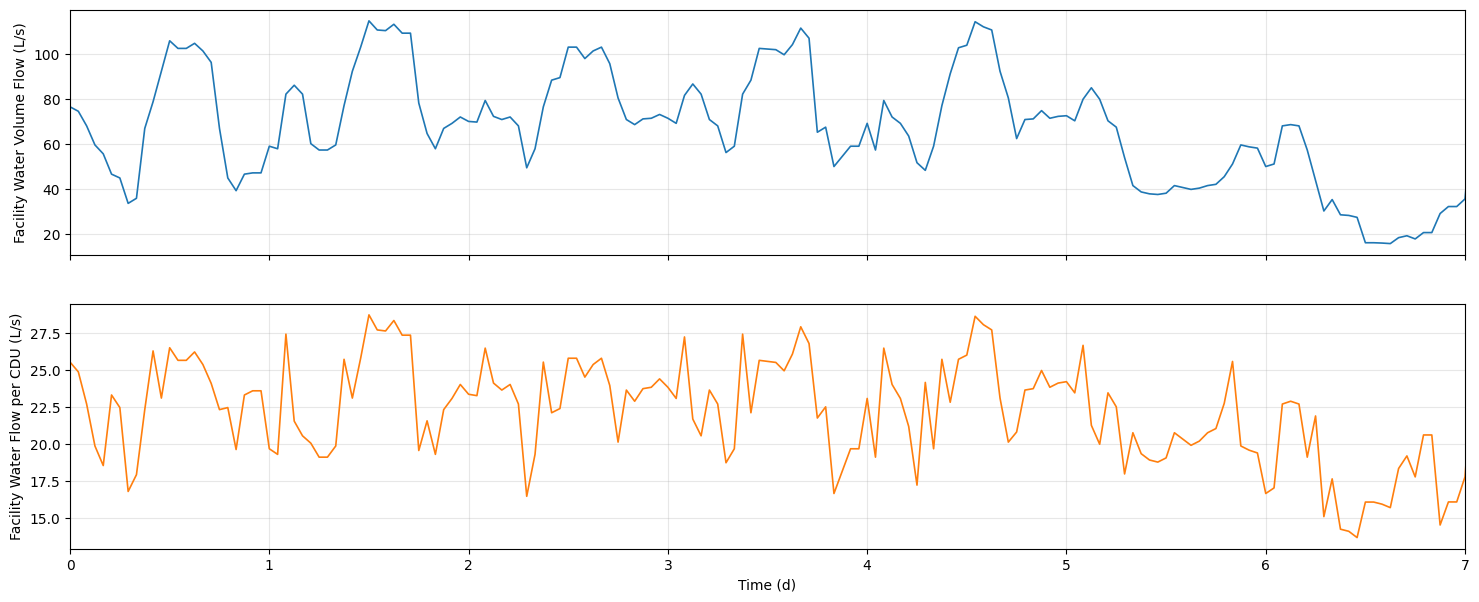

In [7]:
# ---------------------------------------------------------
# Facility Water parameters
# ---------------------------------------------------------

FWS_FLUID = "Water"
T_FWS_SUPPLY = 30.0
T_FWS_RETURN = 40.0
T_FWS_MEAN = (T_FWS_SUPPLY + T_FWS_RETURN) / 2
DT_FWS = T_FWS_RETURN - T_FWS_SUPPLY
P_FWS = 3e5

# ---------------------------------------------------------
# Calculate the water properties at the mean temperature:
# ---------------------------------------------------------

CP_FWS = PropsSI("C", "T", T_FWS_MEAN + 273.15, "P", P_FWS, FWS_FLUID)
RHO_FWS = PropsSI("D", "T", T_FWS_MEAN + 273.15, "P", P_FWS, FWS_FLUID)
print(f"Facility water cp = {CP_FWS:.1f} J/kg-K")
print(f"Facility water density = {RHO_FWS:.1f} kg/m3")

# ---------------------------------------------------------
# Calculating FW mass and volumetric flow rates
# ---------------------------------------------------------

df["Facility Water Heat Load (kW)"] = df["Heat Load (kW)"]
df["Facility Water Mass Flow (kg/s)"] = df["Facility Water Heat Load (kW)"] * 1000 / (CP_FWS * DT_FWS)
df["Facility Water Volume Flow (L/s)"] = df["Facility Water Mass Flow (kg/s)"] / RHO_FWS * 1000
df["Facility Water Flow per CDU (kg/s)"] = df["Facility Water Mass Flow (kg/s)"] / df["CDUs Running"]
df["Facility Water Flow per CDU (L/s)"] = df["Facility Water Volume Flow (L/s)"] / df["CDUs Running"]

# ---------------------------------------------------------
# Checking FWS energy balance
# ---------------------------------------------------------

df["FWS Heat Check (kW)"] = df["Facility Water Mass Flow (kg/s)"] * CP_FWS * DT_FWS / 1000
df["FWS Heat Balance Error (%)"] = (df["FWS Heat Check (kW)"] - df["Heat Load (kW)"]) / df["Heat Load (kW)"] * 100
print(f"Maximum Heat Balance Error (%) {df["FWS Heat Balance Error (%)"].max()} %")
print(f"Minimum Heat Balance Error (%) {df["FWS Heat Balance Error (%)"].min()} %")

# ---------------------------------------------------------
# Plot chip and coolant temperatures
# ---------------------------------------------------------

fig,axes = plt.subplots(2,1,figsize=(18,7),sharex=True)
for idx,var in enumerate(["Facility Water Volume Flow (L/s)","Facility Water Flow per CDU (L/s)"]):
    axes[idx].plot(df["t"]/86400, df[var], label=var, color=colours[idx], linewidth=1.2)
    axes[idx].set_ylabel(var)
    axes[idx].grid(True, alpha=0.3)
axes[-1].set_xlabel("Time (d)")
axes[-1].set_xlim([0,7])

plt.show()

## 7. Facility-Water Pumping Power

Facility water design flow = 130.0 L/s
Design flow per pump = 65.0 L/s
Design power per pump = 17.3 kW


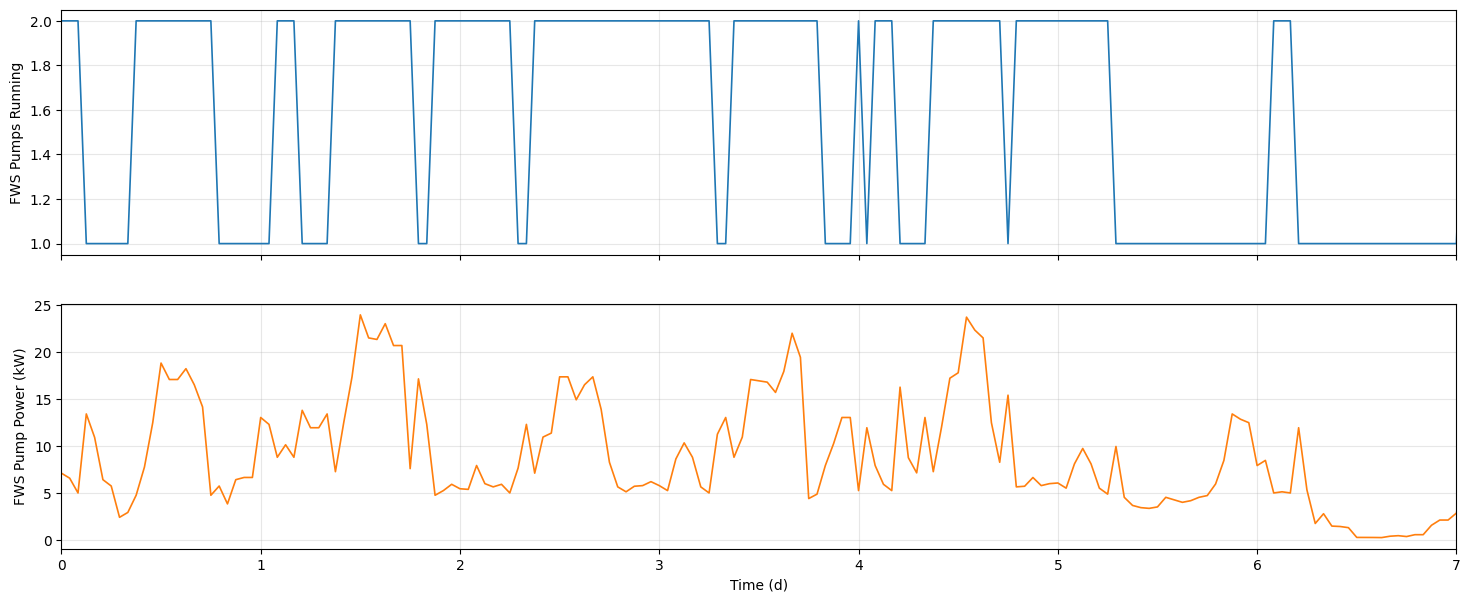

In [8]:
# ---------------------------------------------------------
# FW Pumps Configuration: 3 × 200 kW Pumps, configured as 2 duty + 1 standby (N+1)
# ---------------------------------------------------------

N_FWS_PUMPS = 3
N_FWS_PUMPS_DUTY = 2
FWS_DP_DESIGN = 200000
FWS_PUMP_EFFICIENCY = 0.75

# ---------------------------------------------------------
# Facility-water flow using the full 5.4 MW duty capacity
# ---------------------------------------------------------

FWS_DESIGN_MASS_FLOW = N_CDU_DUTY * CDU_CAPACITY * 1000 / (CP_FWS * DT_FWS)
FWS_DESIGN_VOLUME_FLOW = FWS_DESIGN_MASS_FLOW / RHO_FWS
FWS_FLOW_PER_PUMP = FWS_DESIGN_VOLUME_FLOW / N_FWS_PUMPS_DUTY

# ---------------------------------------------------------
# Electrical power for each 50% pump
# ---------------------------------------------------------

FWS_PUMP_POWER_DESIGN = FWS_DP_DESIGN * FWS_FLOW_PER_PUMP / FWS_PUMP_EFFICIENCY / 1000
print(f"Facility water design flow = {FWS_DESIGN_VOLUME_FLOW * 1000:.1f} L/s")
print(f"Design flow per pump = {FWS_FLOW_PER_PUMP * 1000:.1f} L/s")
print(f"Design power per pump = {FWS_PUMP_POWER_DESIGN:.1f} kW")

# ---------------------------------------------------------
# FW pump scheduling (whether one or two pumps are required)
# ---------------------------------------------------------

df["FWS Pumps Running"] = np.ceil((df["Facility Water Volume Flow (L/s)"] / 1000) / FWS_FLOW_PER_PUMP).clip(1, N_FWS_PUMPS_DUTY).astype(int)
df["FWS Flow per Pump (m3/s)"] = (df["Facility Water Volume Flow (L/s)"] / 1000) / df["FWS Pumps Running"]
df["FWS Pump Speed Fraction"] = (df["FWS Flow per Pump (m3/s)"] / FWS_FLOW_PER_PUMP).clip(0, 1)

# Using an affinity law (P α N^3) the total facility-water pump power becomes:
df["FWS Pump Power (kW)"] = df["FWS Pumps Running"] * FWS_PUMP_POWER_DESIGN * df["FWS Pump Speed Fraction"]**3

# ---------------------------------------------------------
# Plot FW pumps running and FW pumping power
# ---------------------------------------------------------

fig,axes = plt.subplots(2,1,figsize=(18,7),sharex=True)
for idx,var in enumerate(["FWS Pumps Running","FWS Pump Power (kW)"]):
    axes[idx].plot(df["t"]/86400, df[var], label=var, color=colours[idx], linewidth=1.2)
    axes[idx].set_ylabel(var)
    axes[idx].grid(True, alpha=0.3)
axes[-1].set_xlabel("Time (d)")
axes[-1].set_xlim([0,7])

plt.show()

## 8. Waste Heat Utilisation

(0.0, 7.0)

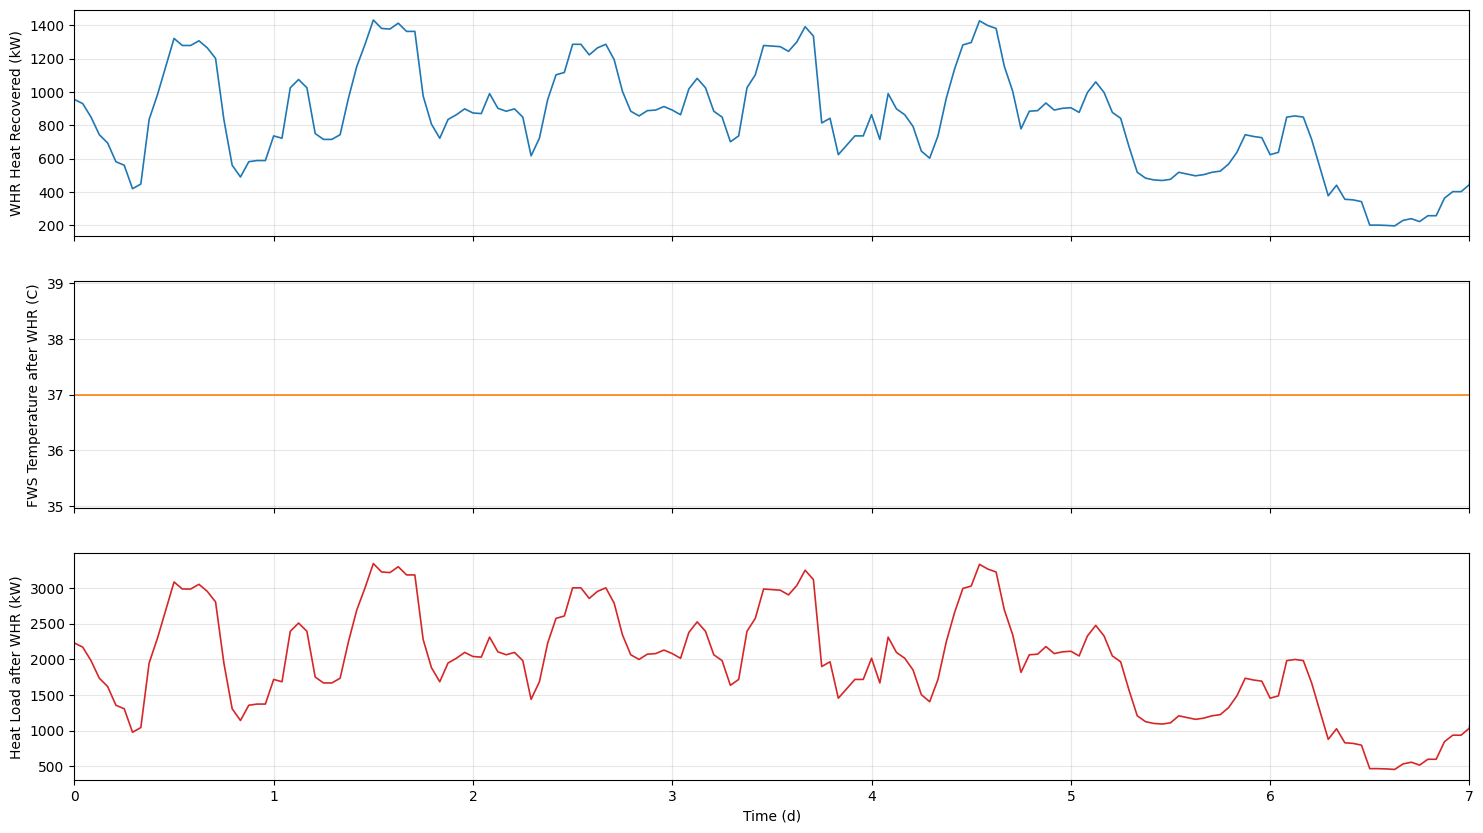

In [9]:
# ---------------------------------------------------------
# WHR operating parameters
# ---------------------------------------------------------

T_WHR_RETURN = 34.0
T_WHR_SUPPLY = 38.0
DT_WHR = T_WHR_SUPPLY - T_WHR_RETURN

# ---------------------------------------------------------
# Minimum temperature approach and source-side thermal limit
# ---------------------------------------------------------

WHR_MIN_APPROACH = 3.0
WHR_FWS_MIN_OUT = T_WHR_RETURN + WHR_MIN_APPROACH
df["WHR Source Maximum (kW)"] = df["Facility Water Mass Flow (kg/s)"] * CP_FWS * np.maximum(T_FWS_RETURN - WHR_FWS_MIN_OUT, 0) / 1000

# ---------------------------------------------------------
# WHR coolant and thermo-physical properties
# ---------------------------------------------------------

WHR_FLUID = "INCOMP::MPG-20%"
P_WHR = 3e5

# WHR-fluid properties
T_WHR_MEAN = (T_WHR_RETURN + T_WHR_SUPPLY) / 2
CP_WHR = PropsSI("C", "T", T_WHR_MEAN + 273.15, "P", P_WHR, WHR_FLUID)
RHO_WHR = PropsSI("D", "T", T_WHR_MEAN + 273.15, "P", P_WHR, WHR_FLUID)

# ---------------------------------------------------------
# Waste heat demand
# ---------------------------------------------------------

WHR_HX_CAPACITY = 2000.0
WASTE_HEAT_DEMAND = 1500.0
df["Waste Heat Demand (kW)"] = WASTE_HEAT_DEMAND

# ---------------------------------------------------------
# Calculating actual WHR duty
# ---------------------------------------------------------

df["WHR Heat Recovered (kW)"] = np.minimum.reduce([df["Facility Water Heat Load (kW)"], df["WHR Source Maximum (kW)"], df["Waste Heat Demand (kW)"], np.full(len(df), WHR_HX_CAPACITY)])

# ---------------------------------------------------------
# Facility-water temperature after WHR
# ---------------------------------------------------------

df["FWS Temperature after WHR (C)"] = T_FWS_RETURN - df["WHR Heat Recovered (kW)"] * 1000 / (df["Facility Water Mass Flow (kg/s)"] * CP_FWS)

# ---------------------------------------------------------
# Heat remaining for the existing heat rejection plant
# ---------------------------------------------------------

df["Heat Load after WHR (kW)"] = df["Facility Water Heat Load (kW)"] - df["WHR Heat Recovered (kW)"]

# ---------------------------------------------------------
# Calculating WHR HTF flow
# ---------------------------------------------------------

df["WHR HTF Mass Flow (kg/s)"] = df["WHR Heat Recovered (kW)"] * 1000 / (CP_WHR * DT_WHR)
df["WHR HTF Volume Flow (L/s)"] = df["WHR HTF Mass Flow (kg/s)"] / RHO_WHR * 1000

# ---------------------------------------------------------
# Plot WHR Heat and temperatures, and heat remaining
# ---------------------------------------------------------

fig,axes = plt.subplots(3,1,figsize=(18,10),sharex=True)
for idx,var in enumerate(["WHR Heat Recovered (kW)","FWS Temperature after WHR (C)","Heat Load after WHR (kW)"]):
    axes[idx].plot(df["t"]/86400, df[var], label=var, color=colours[idx], linewidth=1.2)
    axes[idx].set_ylabel(var)
    axes[idx].grid(True, alpha=0.3)
axes[-1].set_xlabel("Time (d)")
axes[-1].set_xlim([0,7])

## 9. Dry-cooler and Chiller Power Calculation

Design moist-air cp = 1010.6 J/kg-K
Design air mass flow = 534.3 kg/s
Design dry-cooler effectiveness = 0.400
Design dry-cooler UA = 360.0 kW/K
Maximum thermal balance error = 0.000000 kW


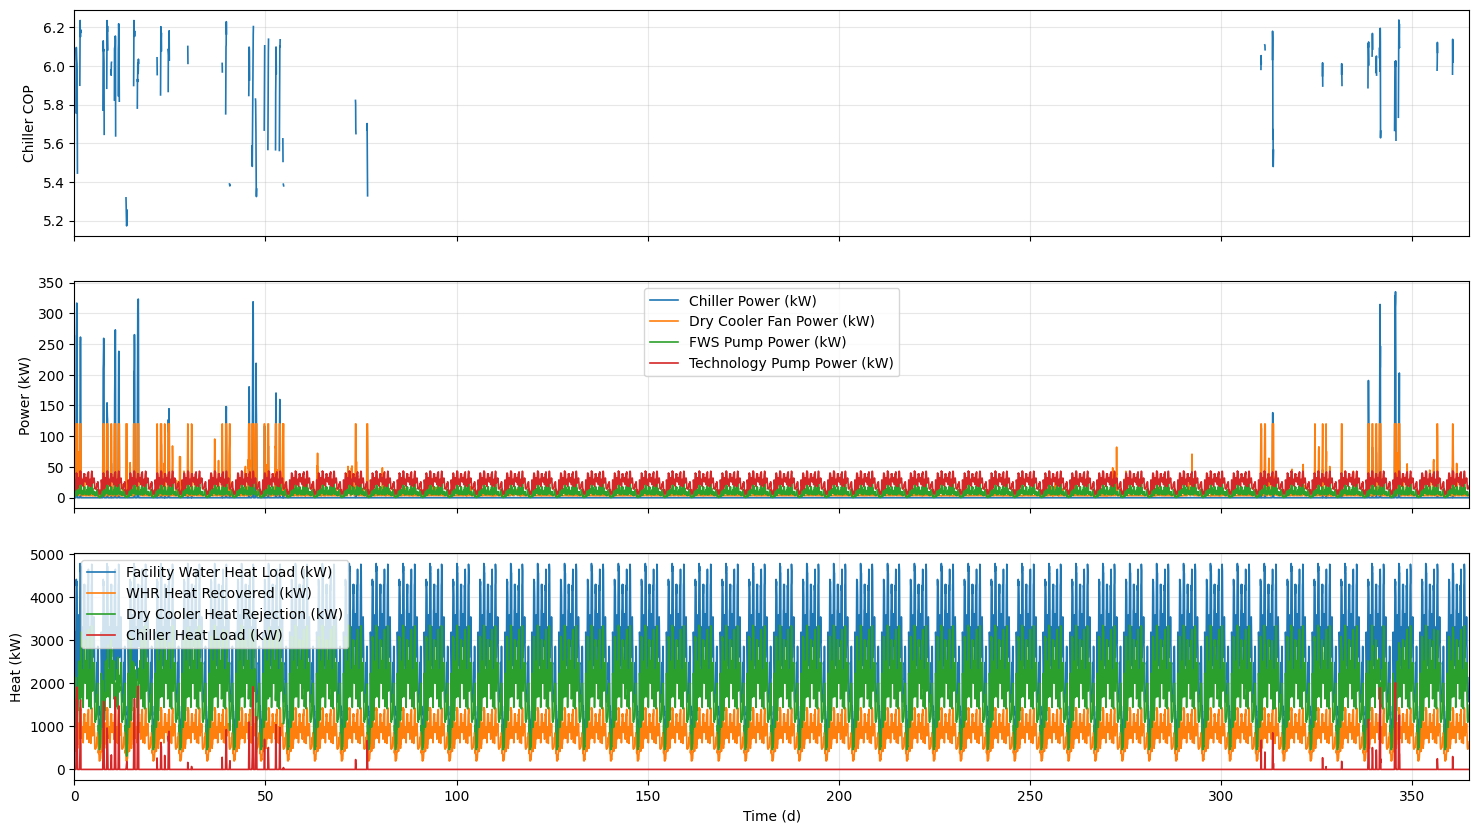

In [10]:
# ---------------------------------------------------------
# CHILLER CAPACITY AND PARAMETERS. COP=5.5 is the reference COP at 35°C dry-bulb near rated operation
# ---------------------------------------------------------

CHILLER_CAPACITY = N_CDU_DUTY * CDU_CAPACITY
CHILLER_COP_REF = 5.5
CHILLER_REF_AMBIENT = 35.0
CHILLER_COP_MIN = 2.5
CHILLER_COP_MAX = 7.0

# ---------------------------------------------------------
# DRY COOLER CAPACITY AND PARAMETERS
# ---------------------------------------------------------

DRY_COOLER_APPROACH = 5.0
DRY_COOLER_CAPACITY = N_CDU_DUTY * CDU_CAPACITY
DRY_COOLER_FAN_POWER_DESIGN = 120.0
DRY_COOLER_MIN_FAN_SPEED = 0.30
DRY_COOLER_DESIGN_AMBIENT = 15.0
DRY_COOLER_DESIGN_AIR_OUTLET = 25.0
DRY_COOLER_DESIGN_RH = 0.50
DRY_COOLER_AIR_CP_DESIGN = HAPropsSI("Cha", "T", DRY_COOLER_DESIGN_AMBIENT + 273.15, "P", 101325, "R", DRY_COOLER_DESIGN_RH)
DRY_COOLER_UA_EXPONENT = 0.60
DRY_COOLER_MIN_FAN_SPEED = 0.30
DRY_COOLER_FAN_POWER_DESIGN = 120.0

# ---------------------------------------------------------
# Deriving the design air flow and UA values
# ---------------------------------------------------------

DC_Q_DESIGN_W = DRY_COOLER_CAPACITY * 1000
DC_AIR_DT_DESIGN = DRY_COOLER_DESIGN_AIR_OUTLET - DRY_COOLER_DESIGN_AMBIENT
DC_AIR_MASS_FLOW_DESIGN = DC_Q_DESIGN_W / (DRY_COOLER_AIR_CP_DESIGN * DC_AIR_DT_DESIGN)
DC_AIR_C_DESIGN = DC_AIR_MASS_FLOW_DESIGN * DRY_COOLER_AIR_CP_DESIGN
DC_WATER_C_DESIGN = FWS_DESIGN_MASS_FLOW * CP_FWS
DC_CMIN_DESIGN = min(DC_AIR_C_DESIGN, DC_WATER_C_DESIGN)
DC_EPS_DESIGN = DC_Q_DESIGN_W / (DC_CMIN_DESIGN * (T_FWS_RETURN - DRY_COOLER_DESIGN_AMBIENT))
DC_NTU_DESIGN = DC_EPS_DESIGN / (1 - DC_EPS_DESIGN)
DRY_COOLER_UA_DESIGN = DC_NTU_DESIGN * DC_CMIN_DESIGN


# ---------------------------------------------------------
# Checking the result of the design
# ---------------------------------------------------------

print(f"Design moist-air cp = {DRY_COOLER_AIR_CP_DESIGN:.1f} J/kg-K")
print(f"Design air mass flow = {DC_AIR_MASS_FLOW_DESIGN:.1f} kg/s")
print(f"Design dry-cooler effectiveness = {DC_EPS_DESIGN:.3f}")
print(f"Design dry-cooler UA = {DRY_COOLER_UA_DESIGN / 1000:.1f} kW/K")

# ---------------------------------------------------------
# DryCooler Function
# ---------------------------------------------------------

def dry_cooler_capacity_kw(m_water, t_water_in, t_air, rh, fan_speed):
    if m_water <= 0 or fan_speed <= 0 or t_air >= t_water_in: return 0.0
    cp_air = HAPropsSI("Cha", "T", t_air + 273.15, "P", 101325, "R", rh)
    c_water = m_water * CP_FWS
    c_air = DC_AIR_MASS_FLOW_DESIGN * fan_speed * cp_air
    c_min = min(c_water, c_air)
    c_max = max(c_water, c_air)
    cr = c_min / c_max
    ua = DRY_COOLER_UA_DESIGN * fan_speed**DRY_COOLER_UA_EXPONENT
    ntu = ua / c_min
    if abs(1 - cr) < 1e-6: eps = ntu / (1 + ntu)
    else: eps = (1 - np.exp(-ntu * (1 - cr))) / (1 - cr * np.exp(-ntu * (1 - cr)))
    return max(0.0, eps * c_min * (t_water_in - t_air) / 1000)

WITH_DRY_COOLER = True
if WITH_DRY_COOLER:

    fan_speed = np.zeros(len(df))
    q_dry = np.zeros(len(df))
    t_dc_out = df["FWS Temperature after WHR (C)"].to_numpy().copy()

    for i in range(len(df)):
        load = df["Heat Load after WHR (kW)"].iloc[i]
        m_water = df["Facility Water Mass Flow (kg/s)"].iloc[i]
        t_water_in = df["FWS Temperature after WHR (C)"].iloc[i]
        t_air = df["Ambient Temperature (C)"].iloc[i]
        rh = df["Relative Humidity (%)"].iloc[i] / 100
        
        if load <= 0 or t_air >= T_FWS_RETURN: continue

        q_full = dry_cooler_capacity_kw(m_water, t_water_in, t_air, rh, 1.0)

        if q_full < load:
            fan_speed[i] = 1.0
            q_dry[i] = q_full
        else:
            q_min = dry_cooler_capacity_kw(m_water, t_water_in, t_air, rh, DRY_COOLER_MIN_FAN_SPEED)

            if q_min >= load:
                fan_speed[i] = DRY_COOLER_MIN_FAN_SPEED
                q_dry[i] = load
            else:
                lo, hi = DRY_COOLER_MIN_FAN_SPEED, 1.0

                for _ in range(25):
                    mid = 0.5 * (lo + hi)
                    if dry_cooler_capacity_kw(m_water, t_water_in, t_air, rh, mid) >= load: hi = mid
                    else: lo = mid

                fan_speed[i] = hi
                q_dry[i] = load

        if m_water > 0: t_dc_out[i] = t_water_in - q_dry[i] * 1000 / (m_water * CP_FWS)

    # Store results
    df["Dry Cooler Fan Speed Fraction"] = fan_speed
    df["Dry Cooler Heat Rejection (kW)"] = q_dry
    df["Dry Cooler Outlet Temperature (C)"] = t_dc_out
    df["Dry Cooler Fan Power (kW)"] = DRY_COOLER_FAN_POWER_DESIGN * df["Dry Cooler Fan Speed Fraction"]**3
else:
    # Store results
    df["Dry Cooler Fan Speed Fraction"] = 0.0
    df["Dry Cooler Heat Rejection (kW)"] = 0.0
    df["Dry Cooler Outlet Temperature (C)"] = T_FWS_RETURN
    df["Dry Cooler Fan Power (kW)"] = 0.0
    
# ---------------------------------------------------------
# Calculate chiller electrical power
# ---------------------------------------------------------

df["Chiller Heat Load (kW)"] = df["Heat Load after WHR (kW)"] - df["Dry Cooler Heat Rejection (kW)"]

df["Chiller PLR"] = (df["Chiller Heat Load (kW)"] / CHILLER_CAPACITY).clip(0, 1)
df["Chiller Temperature Modifier"] = (1 - 0.018 * (df["Ambient Temperature (C)"] - CHILLER_REF_AMBIENT)).clip(0.65, 1.30)
df["Chiller Part Load Modifier"] = (1.06 - 0.50 * (df["Chiller PLR"] - 0.60)**2).clip(0.80, 1.06)

# ---------------------------------------------------------
# Calculate Chiller COP based on Part Load Modifier
# ---------------------------------------------------------

df["Chiller COP"] = CHILLER_COP_REF * df["Chiller Temperature Modifier"] * df["Chiller Part Load Modifier"]
df["Chiller COP"] = df["Chiller COP"].clip(CHILLER_COP_MIN, CHILLER_COP_MAX)
df.loc[df["Chiller Heat Load (kW)"] <= 0, "Chiller COP"] = np.nan

# ---------------------------------------------------------
# Calculate Chiller Power
# ---------------------------------------------------------

df["Chiller Power (kW)"] = np.where(df["Chiller Heat Load (kW)"] > 0, df["Chiller Heat Load (kW)"] / df["Chiller COP"], 0)

# Check the overall heat balance
df["Thermal Balance Error (kW)"] = df["Facility Water Heat Load (kW)"] - df["WHR Heat Recovered (kW)"] - df["Dry Cooler Heat Rejection (kW)"] - df["Chiller Heat Load (kW)"]
print(f"Maximum thermal balance error = {df['Thermal Balance Error (kW)'].abs().max():.6f} kW")

# ---------------------------------------------------------
# Plot WHR Heat and temperatures, and heat remaining
# ---------------------------------------------------------

variables = [
    ["Chiller COP"],
    ["Chiller Power (kW)","Dry Cooler Fan Power (kW)","FWS Pump Power (kW)","Technology Pump Power (kW)",],
    ["Facility Water Heat Load (kW)","WHR Heat Recovered (kW)","Dry Cooler Heat Rejection (kW)","Chiller Heat Load (kW)"]
            ]
ylabels = ["Chiller COP","Power (kW)", "Heat (kW)"]
fig,axes = plt.subplots(3,1,figsize=(18,10),sharex=True)
for idx,var in enumerate(variables):
    for lbx in var:
        axes[idx].plot(df["t"]/86400, df[lbx], label=lbx, linewidth=1.2)
    if len(var)>1:
        axes[idx].legend(loc='best')
    axes[idx].set_ylabel(ylabels[idx])
    axes[idx].grid(True, alpha=0.3)
axes[-1].set_xlabel("Time (d)")
axes[-1].set_xlim([0,365])

plt.show()

## 10. Performance Metrics

Annual mechanical cooling = 167.7 MWh
Annual facility heat load = 24,634.2 MWh
Annual dry-cooler heat rejection = 17,076.2 MWh
Dry-cooling contribution = 69.3%
--------------------------
Annual recovered heat = 7,390.3 MWh
Annual algae heat demand = 13,140.0 MWh
Algae heat demand supplied by WHR = 56.2%
Annual chiller electricity = 27.9 MWh
Annual dry-cooler fan electricity = 82.4 MWh
Annual heat-rejection electricity = 110.3 MWh
Annual facility-water pump electricity = 79.9 MWh
Annual technology-loop pump electricity = 223.1 MWh
Annual cooling electricity = 413.2 MWh
Minimum PUE = 1.012
Maximum PUE = 1.237
Annual cooling-only PUE = 1.017
Chiller = 6.8%
Dry-cooler fans = 19.9%
Facility-water pumps = 19.3%
Technology-loop pumps = 54.0%


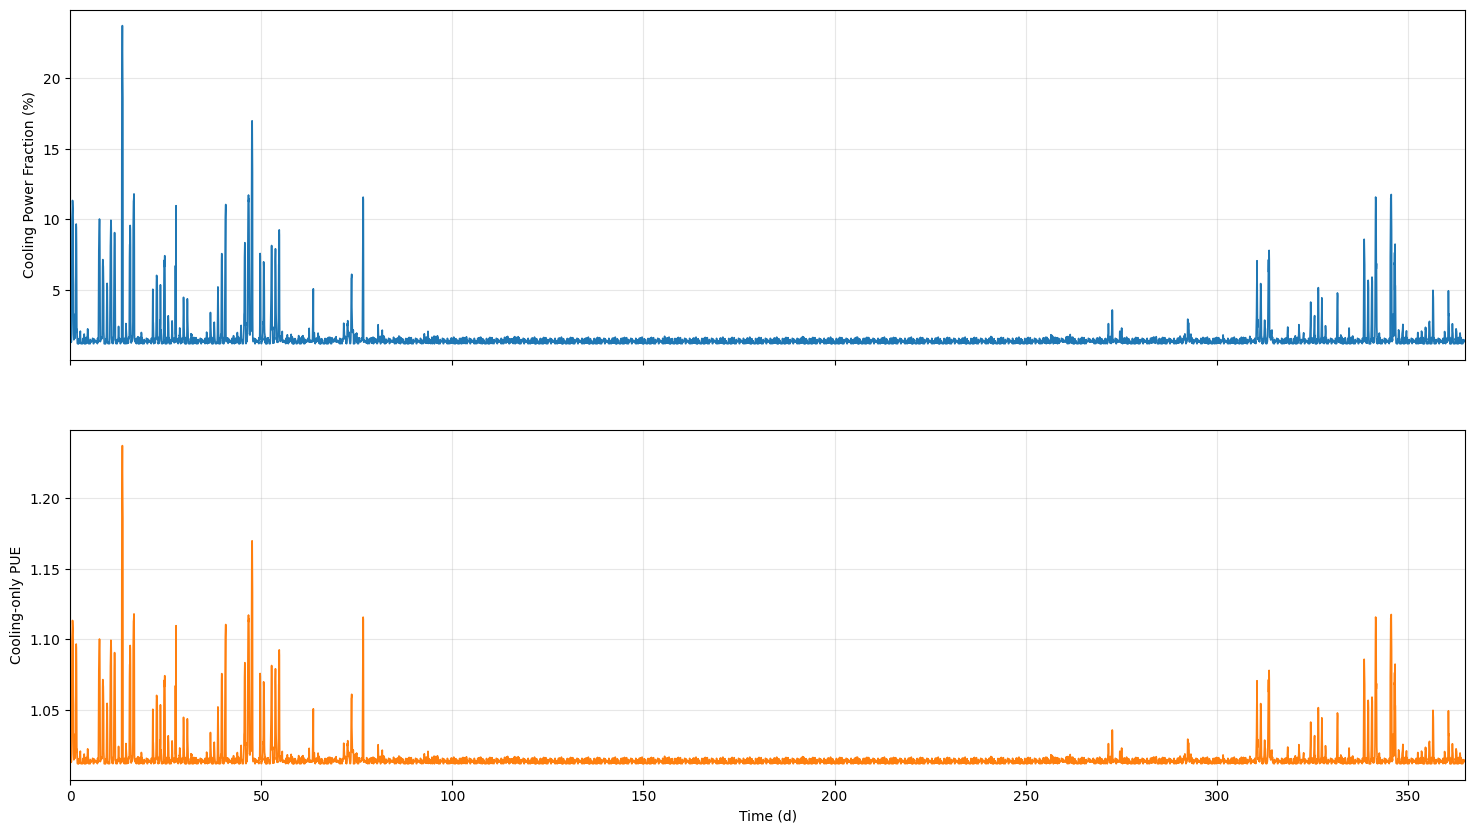

In [11]:
DT_H = df["t"].diff().median() / 3600
CHILLER_COOLING_MWH = df["Chiller Heat Load (kW)"].sum() * DT_H / 1000
TOTAL_HEAT_MWH = df["Facility Water Heat Load (kW)"].sum() * DT_H / 1000
DRY_COOLING_MWH = df["Dry Cooler Heat Rejection (kW)"].sum() * DT_H / 1000
FREE_COOLING_FRACTION = DRY_COOLING_MWH / TOTAL_HEAT_MWH * 100
IT_ENERGY_MWH = df["Heat Load (kW)"].sum() * DT_H / 1000

print(f"Annual mechanical cooling = {CHILLER_COOLING_MWH:,.1f} MWh")
print(f"Annual facility heat load = {TOTAL_HEAT_MWH:,.1f} MWh")
print(f"Annual dry-cooler heat rejection = {DRY_COOLING_MWH:,.1f} MWh")
print(f"Dry-cooling contribution = {FREE_COOLING_FRACTION:.1f}%")
print("--------------------------")

df["Cooling Electrical Power (kW)"] = df["Chiller Power (kW)"] + df["Dry Cooler Fan Power (kW)"] + df["FWS Pump Power (kW)"] + df["Technology Pump Power (kW)"]

WHR_ENERGY_MWH = df["WHR Heat Recovered (kW)"].sum() * DT_H / 1000
print(f"Annual recovered heat = {WHR_ENERGY_MWH:,.1f} MWh")

WASTE_HEAT_DEMAND_MWH = df["Waste Heat Demand (kW)"].sum() * DT_H / 1000
print(f"Annual algae heat demand = {WASTE_HEAT_DEMAND_MWH:,.1f} MWh")

WHR_UTILISATION = WHR_ENERGY_MWH / WASTE_HEAT_DEMAND_MWH * 100 if WASTE_HEAT_DEMAND_MWH>0 else 0.0
print(f"Algae heat demand supplied by WHR = {WHR_UTILISATION:.1f}%")

CHILLER_ENERGY_MWH = df["Chiller Power (kW)"].sum() * DT_H / 1000
print(f"Annual chiller electricity = {CHILLER_ENERGY_MWH:,.1f} MWh")

DRY_COOLER_FAN_ENERGY_MWH = df["Dry Cooler Fan Power (kW)"].sum() * DT_H / 1000
print(f"Annual dry-cooler fan electricity = {DRY_COOLER_FAN_ENERGY_MWH:,.1f} MWh")

df["Heat Rejection Power (kW)"] = df["Chiller Power (kW)"] + df["Dry Cooler Fan Power (kW)"]
HEAT_REJECTION_ENERGY_MWH = df["Heat Rejection Power (kW)"].sum() * DT_H / 1000
print(f"Annual heat-rejection electricity = {HEAT_REJECTION_ENERGY_MWH:,.1f} MWh")

FWS_PUMP_ENERGY_MWH = df["FWS Pump Power (kW)"].sum() * DT_H / 1000
print(f"Annual facility-water pump electricity = {FWS_PUMP_ENERGY_MWH:,.1f} MWh")

TECH_PUMP_ENERGY_MWH = df["Technology Pump Power (kW)"].sum() * DT_H / 1000
print(f"Annual technology-loop pump electricity = {TECH_PUMP_ENERGY_MWH:,.1f} MWh")

COOLING_ENERGY_MWH = df["Cooling Electrical Power (kW)"].sum() * DT_H / 1000
print(f"Annual cooling electricity = {COOLING_ENERGY_MWH:,.1f} MWh")

df["Cooling Power Fraction (%)"] = df["Cooling Electrical Power (kW)"] / df["Heat Load (kW)"] * 100

df["Cooling-only PUE"] = (df["Heat Load (kW)"] + df["Cooling Electrical Power (kW)"]) / df["Heat Load (kW)"]
print(f"Minimum PUE = {df['Cooling-only PUE'].min():.3f}")
print(f"Maximum PUE = {df['Cooling-only PUE'].max():.3f}")

# -------------------------
ANNUAL_COOLING_PUE = (IT_ENERGY_MWH + COOLING_ENERGY_MWH) / IT_ENERGY_MWH
print(f"Annual cooling-only PUE = {ANNUAL_COOLING_PUE:.3f}")

print(f"Chiller = {CHILLER_ENERGY_MWH / COOLING_ENERGY_MWH * 100:.1f}%")
print(f"Dry-cooler fans = {DRY_COOLER_FAN_ENERGY_MWH / COOLING_ENERGY_MWH * 100:.1f}%")
print(f"Facility-water pumps = {FWS_PUMP_ENERGY_MWH / COOLING_ENERGY_MWH * 100:.1f}%")
print(f"Technology-loop pumps = {TECH_PUMP_ENERGY_MWH / COOLING_ENERGY_MWH * 100:.1f}%")

# ---------------------------------------------------------
# Plot WHR Heat and temperatures, and heat remaining
# ---------------------------------------------------------

variables =  ["Cooling Power Fraction (%)","Cooling-only PUE"]
fig,axes = plt.subplots(2,1,figsize=(18,10),sharex=True)
for idx,var in enumerate(variables):
    axes[idx].plot(df["t"]/86400, df[var], label=var, color=colours[idx], linewidth=1.2)
    axes[idx].set_ylabel(var)
    axes[idx].grid(True, alpha=0.3)
axes[-1].set_xlabel("Time (d)")
axes[-1].set_xlim([0,365])

plt.show()

### 10.1 Maximum and minimum PUE

In [12]:
cols = ["t", "Heat Load (kW)", "Ambient Temperature (C)", "Dry Cooler Heat Rejection (kW)", "Chiller Heat Load (kW)", "Chiller Power (kW)", "Dry Cooler Fan Power (kW)", "FWS Pump Power (kW)", "Cooling Electrical Power (kW)", "Cooling-only PUE"]
display(df.loc[[df["Cooling-only PUE"].idxmin(), df["Cooling-only PUE"].idxmax()], cols])

,t,Heat Load (kW),Ambient Temperature (C),Dry Cooler Heat Rejection (kW),Chiller Heat Load (kW),Chiller Power (kW),Dry Cooler Fan Power (kW),FWS Pump Power (kW),Cooling Electrical Power (kW),Cooling-only PUE
90,324000,2713.075,15.30,1899.152500,0.000000,0.000000,3.24,4.396239,32.204008,1.011870
328,1180800,653.335,32.25,308.184883,149.149617,28.832119,120.00,0.245563,154.993841,1.237235


## 11. Exporting results

In [13]:
df.to_csv(OUTPUT_DIR / f"datacentre_WHR_assessment_{YEAR}_detailed.csv", index=False)